# Prediksi Harga Laptop dengan Random Forest Regressor

**Tujuan:** membuat model machine learning yang dapat memprediksi **harga laptop** (`Price`) berdasarkan spesifikasinya.

**Jenis masalah:** *regresi*, karena yang diprediksi adalah angka kontinu (harga), bukan kategori.

**Dataset:** `Laptop_price.csv`, 1.000 baris dan 7 kolom.

| Kolom | Keterangan |
|---|---|
| `Brand` | Merek laptop (Asus, Acer, Lenovo, HP, Dell) |
| `Processor_Speed` | Kecepatan prosesor (GHz) |
| `RAM_Size` | Ukuran RAM (GB) |
| `Storage_Capacity` | Kapasitas penyimpanan (GB) |
| `Screen_Size` | Ukuran layar (inci) |
| `Weight` | Berat laptop (kg) |
| `Price` | Harga laptop (**target** yang diprediksi) |

**Alur notebook:** Import library → Load data → Pengecekan data → EDA → Pemilihan fitur → Split data → Modeling (Random Forest + GridSearchCV) → Evaluasi → Kesimpulan

## 1. Import Library

Library yang dipakai pada tahap awal:
- **pandas**: membaca dan mengolah data tabel (DataFrame)
- **numpy**: operasi numerik
- **seaborn** dan **matplotlib**: membuat grafik dan visualisasi

Library untuk modeling (scikit-learn) di-import nanti, tepat sebelum dipakai.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## 2. Load Data

Membaca file CSV ke dalam DataFrame `df`. Pastikan file `Laptop_price.csv` berada di folder yang sama dengan notebook (di Google Colab, upload dulu ke sesi).

In [2]:
df = pd.read_csv('Laptop_price.csv')

In [3]:
df

,Brand,Processor_Speed,RAM_Size,Storage_Capacity,Screen_Size,Weight,Price
0,Asus,3.830296,16,512,11.185147,2.641094,17395.093065
1,Acer,2.912833,4,1000,11.311372,3.260012,31607.605919
2,Lenovo,3.241627,4,256,11.853023,2.029061,9291.023542
3,Acer,3.806248,16,512,12.280360,4.573865,17436.728334
4,Acer,3.268097,32,1000,14.990877,4.193472,32917.990718
...,...,...,...,...,...,...,...
995,HP,3.343584,4,1000,12.587095,3.162399,31593.668017
996,Dell,2.780555,8,256,12.679356,3.750265,9149.521832
997,Dell,3.200569,4,512,12.666315,3.392612,16552.404779
998,Asus,1.604182,8,256,11.215581,3.857613,9407.473459


## 3. Pengecekan Data

Sebelum analisis dan modeling, kualitas data dicek terlebih dahulu:

1. **Ukuran data dan tipe kolom** (`shape`, `info()`): ada 1.000 baris dan 7 kolom. `Brand` bertipe `object` (teks), sisanya numerik.
2. **Missing value** (`isna().sum()`): semua kolom bernilai 0, jadi tidak ada data kosong.
3. **Data duplikat** (`duplicated().sum()`): hasilnya 0, tidak ada baris ganda.
4. **Statistik deskriptif** (`describe()`): menampilkan rata-rata, standar deviasi, nilai minimum, kuartil, dan maksimum tiap kolom numerik.

**Kesimpulan:** data bersih, jadi tidak perlu *imputasi* maupun penghapusan baris. Kolom `RAM_Size` hanya berisi nilai 4, 8, 16, 32 GB, dan `Storage_Capacity` berkisar 256 sampai 1000 GB, sehingga keduanya bersifat diskrit.

In [4]:
print(f'Baris : {df.shape[0]}')
print(f'Kolom : {df.shape[1]}')
df.info()

Baris : 1000
Kolom : 7
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Brand             1000 non-null   str    
 1   Processor_Speed   1000 non-null   float64
 2   RAM_Size          1000 non-null   int64  
 3   Storage_Capacity  1000 non-null   int64  
 4   Screen_Size       1000 non-null   float64
 5   Weight            1000 non-null   float64
 6   Price             1000 non-null   float64
dtypes: float64(4), int64(2), str(1)
memory usage: 58.7 KB


In [5]:
df.isna().sum()

Brand               0
Processor_Speed     0
RAM_Size            0
Storage_Capacity    0
Screen_Size         0
Weight              0
Price               0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.describe()

,Processor_Speed,RAM_Size,Storage_Capacity,Screen_Size,Weight,Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,2.750611,15.500000,584.576000,14.056790,3.466919,19604.187963
std,0.731796,10.988665,313.438517,1.705882,0.866541,9406.064880
min,1.511580,4.000000,256.000000,11.012111,2.000560,8570.012950
25%,2.089246,8.000000,256.000000,12.635523,2.717211,10114.012948
50%,2.760885,16.000000,512.000000,14.099643,3.464630,17287.241878
75%,3.362610,32.000000,1000.000000,15.528590,4.212583,31566.214754
max,3.998534,32.000000,1000.000000,16.985737,4.990728,33503.935037


## 4. Exploratory Data Analysis (EDA)

EDA dipakai untuk memahami pola data sebelum modeling.

### 4.1 Rata-rata Harga per Brand

Data dikelompokkan per `Brand`, lalu dihitung rata-rata `Price`, dan hasilnya divisualisasikan dengan diagram batang.

**Temuan:** Acer paling tinggi (≈ 19.985) dan Dell paling rendah (≈ 18.866). Selisihnya hanya sekitar 5,6%, jadi **merek tidak banyak memengaruhi harga**.

> **Catatan:** dataset tidak menyebut satuan mata uang, sehingga harga ditampilkan tanpa label "Rp." atau simbol mata uang lain.

In [8]:
df.groupby('Brand')['Price'].mean().sort_values(ascending=False).apply(lambda x: f'{x:,.2f}').to_frame('Rata-rata Harga')

,Rata-rata Harga
Brand,
Acer,"19,984.61"
Lenovo,"19,974.93"
Asus,"19,854.24"
HP,"19,369.76"
Dell,"18,866.01"


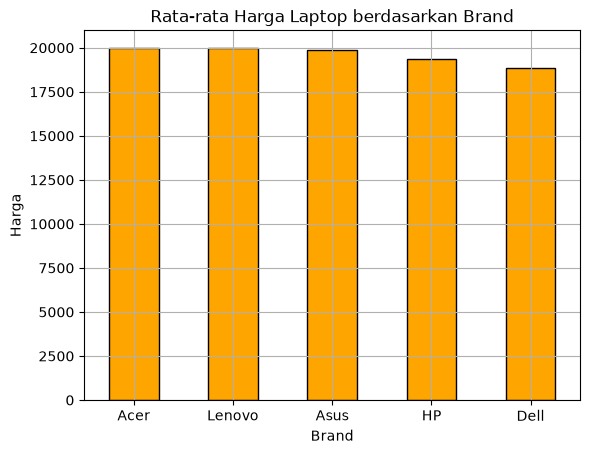

In [9]:
df.groupby('Brand')['Price'].mean().sort_values(ascending=False).plot(kind='bar',color='orange',edgecolor='black')
plt.title('Rata-rata Harga Laptop berdasarkan Brand')
plt.xlabel('Brand')
plt.ylabel('Harga')
plt.grid(True)
plt.xticks(rotation=0)
plt.show()

### 4.2 Sebaran Brand pada Tiap Ukuran RAM

Menghitung jumlah laptop tiap brand untuk setiap ukuran RAM (4, 8, 16, 32 GB). Tujuannya melihat apakah ada brand yang dominan pada konfigurasi tertentu.

**Temuan:** sebarannya cukup merata. Tidak ada brand yang hanya menjual satu jenis RAM, sehingga tidak ada bias besar dari kombinasi brand dan RAM.

In [10]:
df.groupby('RAM_Size')['Brand'].value_counts()

RAM_Size  Brand 
4         HP        59
          Acer      50
          Dell      48
          Asus      47
          Lenovo    39
8         Asus      66
          Lenovo    51
          Acer      48
          Dell      43
          HP        38
16        Dell      52
          HP        49
          Asus      47
          Acer      47
          Lenovo    42
32        Dell      67
          Acer      59
          Lenovo    58
          Asus      46
          HP        44
Name: count, dtype: int64

### 4.3 Korelasi Antar Fitur Numerik

Heatmap dan daftar korelasi menunjukkan kekuatan hubungan linear tiap fitur dengan `Price`. Nilai mendekati **1** atau **-1** berarti hubungan kuat, dan mendekati **0** berarti hampir tidak ada hubungan.

**Temuan penting:**

| Fitur | Korelasi dengan Price |
|---|---|
| `Storage_Capacity` | **0,998** (sangat kuat) |
| `RAM_Size` | 0,061 |
| `Weight` | 0,038 |
| `Screen_Size` | -0,027 |
| `Processor_Speed` | -0,051 |

`Storage_Capacity` hampir sepenuhnya menentukan harga, sedangkan fitur lain berkorelasi sangat lemah. Artinya harga laptop pada dataset ini hampir seluruhnya ditentukan oleh kapasitas penyimpanan.

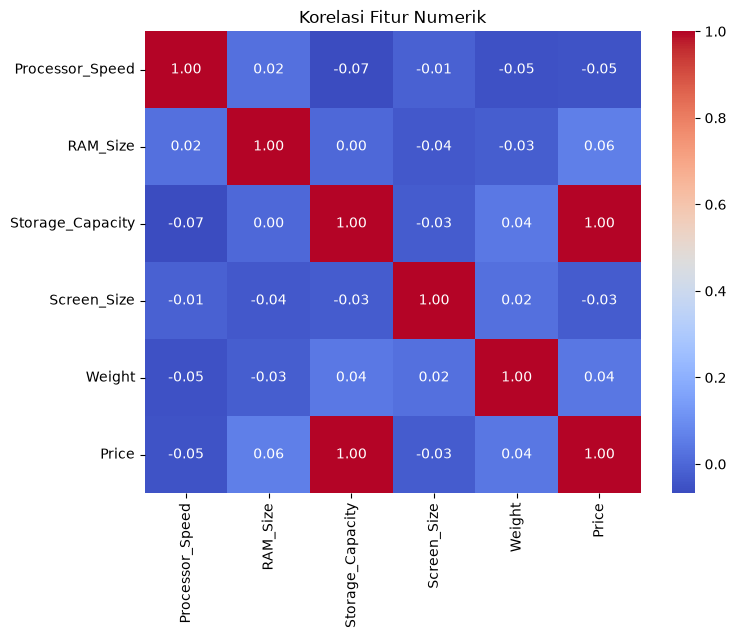

Korelasi terhadap Price:
Storage_Capacity    0.997908
RAM_Size            0.061237
Weight              0.038417
Screen_Size        -0.026740
Processor_Speed    -0.050737
Name: Price, dtype: float64


In [11]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.drop(columns='Brand').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Korelasi Fitur Numerik')
plt.show()

print('Korelasi terhadap Price:')
print(df.drop(columns='Brand').corr()['Price'].drop('Price').sort_values(ascending=False))

### 4.4 Proporsi Brand

Menghitung jumlah dan persentase tiap brand. Hasilnya: Dell (210), Asus (206), Acer (204), Lenovo (190), HP (190). Distribusinya relatif seimbang, tidak ada brand yang mendominasi.

In [12]:
df['Brand'].value_counts()

Brand
Dell      210
Asus      206
Acer      204
Lenovo    190
HP        190
Name: count, dtype: int64

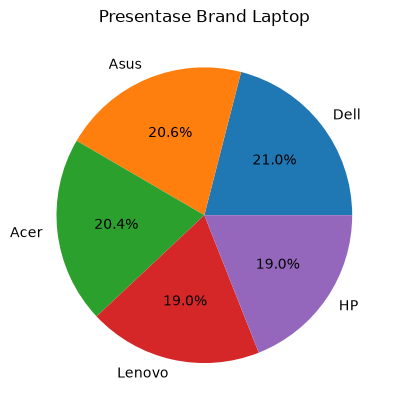

In [13]:
df['Brand'].value_counts().plot(kind='pie',autopct='%1.1f%%')
plt.title('Presentase Brand Laptop')
plt.ylabel('')
plt.show()

## 5. Pemilihan Fitur

Daftar kolom ditampilkan dulu, lalu data dipisah menjadi:
- **X (fitur/input):** `Processor_Speed`, `RAM_Size`, `Storage_Capacity`
- **y (target/output):** `Price`

**Alasan pemilihan:**
- `Brand` tidak dipakai karena rata-rata harga antar brand hampir sama (bagian 4.1) dan berupa teks (butuh encoding tambahan).
- `Screen_Size` dan `Weight` tidak dipakai karena korelasinya terhadap harga sangat rendah (bagian 4.3).
- `Storage_Capacity` wajib dipakai karena paling berpengaruh. `RAM_Size` dan `Processor_Speed` tetap disertakan karena secara spesifikasi relevan terhadap harga, walau korelasi linearnya lemah di dataset ini.

In [14]:
df.columns.tolist()

['Brand',
 'Processor_Speed',
 'RAM_Size',
 'Storage_Capacity',
 'Screen_Size',
 'Weight',
 'Price']

In [15]:
X = df[['Processor_Speed','RAM_Size','Storage_Capacity']]
y = df['Price']

## 6. Pembagian Data (Train-Test Split)

Data dibagi menjadi:
- **Data latih (80%)**: 800 baris, untuk melatih model
- **Data uji (20%)**: 200 baris, untuk menguji model pada data yang belum pernah dilihat

`random_state=42` membuat pembagiannya selalu sama setiap notebook dijalankan, sehingga hasil bisa direproduksi.

In [16]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [17]:
print(f'Training : {X_train.shape[0]}')
print(f'Testing : {X_test.shape[0]}')

Training : 800
Testing : 200


## 7. Modeling

### 7.1 Random Forest Regressor

**Random Forest** adalah gabungan banyak *decision tree*. Tiap pohon dilatih pada sampel data yang sedikit berbeda, lalu prediksi akhirnya adalah **rata-rata prediksi semua pohon**. Cara ini membuat model lebih stabil dan tidak mudah overfitting dibanding satu pohon tunggal, serta tidak membutuhkan penskalaan fitur.

Di sini model dibuat dengan `random_state=42` agar hasilnya konsisten setiap dijalankan, lalu parameternya dicari lewat GridSearchCV.

In [18]:
from sklearn.ensemble import RandomForestRegressor

In [19]:
rfr = RandomForestRegressor(random_state=42)

### 7.2 Hyperparameter Tuning dengan GridSearchCV

**GridSearchCV** mencoba semua kombinasi parameter, menilainya dengan *cross-validation*, lalu memilih kombinasi terbaik secara otomatis.

In [20]:
from sklearn.model_selection import GridSearchCV

Parameter yang diuji:

| Parameter | Arti | Nilai yang dicoba |
|---|---|---|
| `max_depth` | Kedalaman maksimum tiap pohon (makin dalam makin kompleks) | 5, 10, 15, 20, 25 |
| `max_features` | Jumlah fitur yang dipertimbangkan di tiap percabangan | `'sqrt'`, `'log2'`, `1.0` (semua fitur) |
| `n_estimators` | Jumlah pohon dalam hutan | 50, 100, 200 |

Total ada 5 × 3 × 3 = **45 kombinasi**.

> **Perbaikan:** opsi `max_features='auto'` sebelumnya sudah dihapus di scikit-learn versi baru sehingga membuat separuh fit gagal. Opsi tersebut diganti `'sqrt'` dan `1.0`. Rentang `n_estimators` juga dinaikkan karena 2 sampai 10 pohon terlalu sedikit untuk Random Forest.

In [21]:
param_grid = {'max_depth' : [5,10,15,20,25],'max_features':['sqrt','log2',1.0],'n_estimators':[50,100,200]}

Pengaturan GridSearchCV:
- `cv=5`: *5-fold cross-validation*. Data latih dibagi 5 bagian; model dilatih pada 4 bagian dan diuji pada 1 bagian secara bergantian. Totalnya 45 kombinasi × 5 = **225 fit**.
- `scoring='neg_mean_squared_error'`: kombinasi terbaik dipilih berdasarkan MSE terkecil. Nilainya negatif karena scikit-learn selalu memaksimalkan skor.
- `n_jobs=-1`: memakai semua core CPU agar proses lebih cepat.

In [22]:
grid_rfr = GridSearchCV(rfr,param_grid,cv=5,scoring='neg_mean_squared_error',n_jobs=-1)

Proses pelatihan dijalankan. Setelah perbaikan `max_features`, seharusnya **tidak ada lagi `FitFailedWarning`**, karena seluruh 225 fit valid. Pada versi sebelumnya, `'auto'` membuat 150 dari 300 fit gagal.

Jika peringatan masih muncul, periksa kembali isi `param_grid` dan versi scikit-learn yang dipakai.

In [23]:
grid_rfr.fit(X_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [5, 10, ...], 'max_features': ['sqrt', 'log2', ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose ver

### 7.3 Parameter Terbaik

Sel berikut menampilkan kombinasi `max_depth`, `max_features`, dan `n_estimators` terbaik menurut GridSearchCV. Karena sekarang seluruh kombinasi valid, hasilnya dipilih dari semua 45 kombinasi, bukan hanya separuhnya.

In [24]:
grid_rfr.best_params_

{'max_depth': 5, 'max_features': 1.0, 'n_estimators': 200}

## 8. Prediksi dan Evaluasi Model

`grid_rfr.predict(X_test)` memakai model terbaik untuk memprediksi harga pada **data uji**, yaitu data yang tidak dipakai saat pelatihan, sehingga hasilnya menggambarkan performa model di dunia nyata.

In [25]:
prediksi = grid_rfr.predict(X_test)

### 8.1 Metrik Evaluasi

Tiga metrik regresi dihitung dengan membandingkan harga asli (`y_test`) dan harga prediksi (`prediksi`):

| Metrik | Arti | Semakin... |
|---|---|---|
| **MAE** (Mean Absolute Error) | Rata-rata selisih absolut prediksi dan harga asli, dalam satuan harga | kecil semakin baik |
| **MSE** (Mean Squared Error) | Rata-rata kuadrat selisih; menghukum kesalahan besar lebih berat, satuannya kuadrat harga | kecil semakin baik |
| **R²** (R-squared) | Proporsi variasi harga yang bisa dijelaskan model (0 sampai 1) | besar (mendekati 1) semakin baik |

In [26]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [27]:
mae = mean_absolute_error(y_test,prediksi)
mse = mean_squared_error(y_test,prediksi)
r2 = r2_score(y_test,prediksi)

In [28]:
rmse = mse ** 0.5
print(f'MAE  : {mae:.2f}')
print(f'MSE  : {mse:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'R2   : {r2:.4f}  ({r2 * 100:.2f}%)')
print(f'MAE terhadap rata-rata harga : {mae / y.mean() * 100:.2f}%')

MAE  : 154.56
MSE  : 36779.51
RMSE : 191.78
R2   : 0.9996  (99.96%)
MAE terhadap rata-rata harga : 0.79%


### 8.2 Interpretasi Hasil

Semua metrik dicetak **apa adanya** (tanpa dikali 100):

| Metrik | Satuan | Cara membaca |
|---|---|---|
| MAE | satuan harga | Rata-rata prediksi meleset sebesar nilai ini dari harga asli |
| MSE | satuan harga kuadrat | Sulit dibaca langsung, karena itu dihitung juga RMSE |
| RMSE | satuan harga | Akar MSE; lebih besar dari MAE bila ada kesalahan prediksi yang besar |
| R² | tanpa satuan (0 sampai 1) | Proporsi variasi harga yang dijelaskan model; boleh ditulis sebagai persen |
| MAE terhadap rata-rata harga | persen | Ukuran kesalahan relatif; makin kecil makin baik |

**Panduan menilai:** R² di atas 0,9 dan MAE di bawah sekitar 5% dari rata-rata harga menandakan model yang sangat baik.

> **Perbaikan:** sebelumnya MAE dan MSE dikali 100 dan diberi tanda `%`. Itu keliru karena keduanya bukan persentase. Kini hanya R² yang ditampilkan sebagai persen, dan ditambahkan persentase kesalahan relatif yang dihitung dengan benar.

## 9. Kesimpulan

1. **Data** berkualitas baik: 1.000 baris, tanpa missing value dan tanpa duplikat.
2. **Faktor penentu harga:** `Storage_Capacity` berkorelasi **0,998** dengan `Price`, jauh melampaui fitur lain. Merek, ukuran layar, dan berat hampir tidak berpengaruh.
3. **Model:** Random Forest Regressor yang parameternya dipilih lewat GridSearchCV (45 kombinasi, 5-fold cross-validation, semuanya valid).
4. **Performa pada data uji:** lihat nilai MAE, RMSE, R², dan persentase kesalahan relatif pada output bagian 8. *(Tulis angka hasil run terbaru di sini.)*
5. Karena harga pada dataset ini hampir linear terhadap kapasitas penyimpanan, performa model diperkirakan sangat baik.

### Saran pengembangan
- Bandingkan dengan model baseline (misalnya Linear Regression) untuk memastikan Random Forest memang lebih baik.
- Cek overfitting dengan membandingkan R² data latih dan data uji.
- Tampilkan *feature importance* dan grafik harga aktual vs prediksi.